---
# Nicht-lineare Klassifikation mittels SVM mit RBF-Kernel


---
# Vorbereitung - Dependencies

In [6]:
# (1) Mathe / Data Science
import numpy as np
import pandas as pd

# (2) scikit-learn: SVM
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# (3) Visualisierung
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from helpers import scatter_classes, plot_svm, legend_handles, GREY, LIGHT_GREY, BLACK, COLOR_C_1, COLOR_C_2, BG_CMAP

# Darstellung der Plots innerhalb des Notebooks
%matplotlib inline

## Daten

class counts: {1: 150, -1: 150}


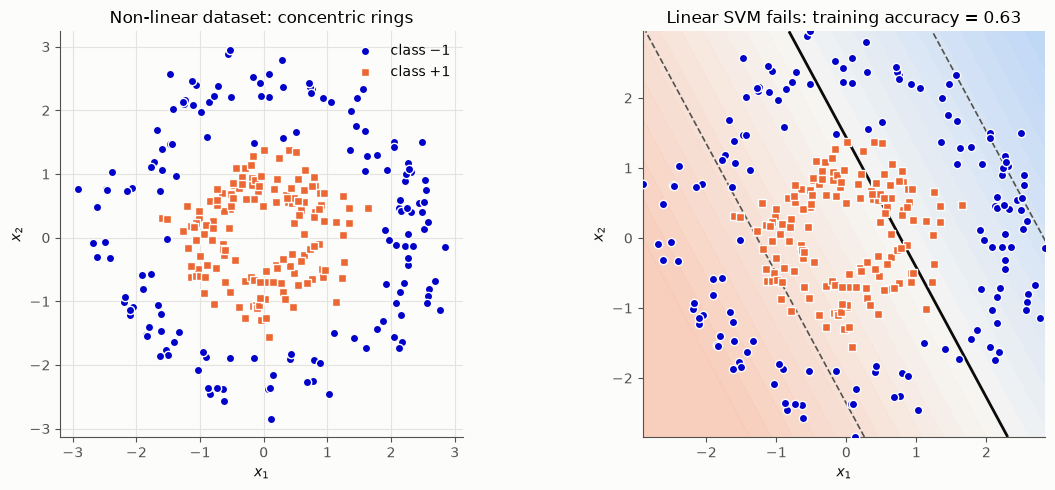

In [ ]:
# (1) Laden der Daten
nl = pd.read_csv("data/nonlinear_data.csv")
X_nl = nl[["x1", "x2"]].to_numpy()
y_nl = nl["label"].to_numpy()

# (2) Debugging
print("class counts:", nl["label"].value_counts().to_dict())



In [ ]:
# (1) Training der linearen SVM
lin_try = SVC(kernel="linear", C=1).fit(X_nl, y_nl)

# (2) Plots
# Zwei Plots: die Rohdaten (links) und die fehlschlagende lineare SVM (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
scatter_classes(ax1, X_nl, y_nl)
ax1.set_title("Nicht lineares Dataset: konzentrische Ringe"); ax1.legend(loc="upper right"); ax1.set_aspect("equal")

plot_svm(ax2, lin_try, X_nl, y_nl, f"Lineare SVM: mit Trainings Eval: = {lin_try.score(X_nl, y_nl):.2f}", show_sv=False)
ax2.set_aspect("equal")

plt.tight_layout()
plt.show()

The linear SVM is only slightly better than chance (50 % for two balanced classes): the classes are **not linearly separable** in $(x_1, x_2)$.

## 2.2 Idee der expliziten Transformation in höhere Dimension mit feature map $\phi(x)$

Suppose we add a third feature, the squared distance from the origin:

$$
\phi(x_1, x_2) = \big(x_1,\ x_2,\ x_1^2 + x_2^2\big).
$$

In this 3-D **feature space** the inner ring is "low" and the outer ring is "high", so a flat plane
$x_1^2 + x_2^2 = \text{const}$ separates them. A **linear** classifier in feature space corresponds to a
**non-linear** (here: circular) boundary in the original space.

linear SVM in feature space: training accuracy = 0.983


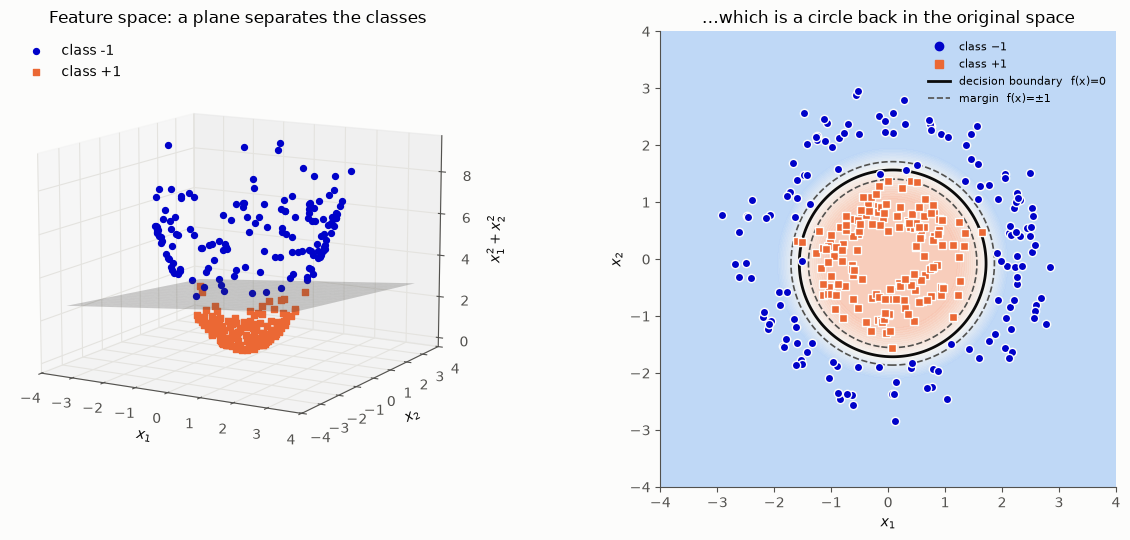

In [8]:
# TODO: OPTIONAL - RAUSNEHMEN?
# Explizite Feature Map phi(x) = (x1, x2, x1^2 + x2^2): der quadrierte Abstand vom Ursprung wird als drittes Feature hinzugefuegt
r2 = (X_nl ** 2).sum(axis=1)
# Die Originalfeatures mit r2 zur 3-D Feature Matrix Phi zusammenfuegen
Phi = np.c_[X_nl, r2]
# Lineare SVM im 3-D Feature Raum trainieren (dort lassen sich die Ringe jetzt trennen)
lin3d = SVC(kernel="linear", C=1).fit(Phi, y_nl)
# Gewichtsvektor und Bias der trennenden Ebene im Feature Raum
w3, b3 = lin3d.coef_[0], lin3d.intercept_[0]
# Trainingsgenauigkeit im Feature Raum sollte (fast) 100 % sein
print(f"linear SVM in feature space: training accuracy = {lin3d.score(Phi, y_nl):.3f}")

# Abbildung mit einem 3-D Plot (links) und einem 2-D Plot (rechts)
fig = plt.figure(figsize=(13, 5.5))
# Links: 3-D Scatter Plot der Punkte im Feature Raum
ax = fig.add_subplot(1, 2, 1, projection="3d")
# Jede Klasse mit ihrer Farbe und ihrem Marker zeichnen
for lab, col, mk in [(-1, COLOR_C_1, "o"), (1, COLOR_C_2, "s")]:
    ax.scatter(*Phi[y_nl == lab].T, c=col, marker=mk, s=18, depthshade=False, label=f"class {lab:+d}")
# Gitter ueber x1 und x2, um die trennende Ebene zu zeichnen
gx, gy = np.meshgrid(np.linspace(-3.5, 3.5, 20), np.linspace(-3.5, 3.5, 20))
gz = -(w3[0] * gx + w3[1] * gy + b3) / w3[2]          # trennende Ebene im Feature Raum
# Die Ebene als halbtransparente Flaeche zeichnen
ax.plot_surface(gx, gy, gz, color=GREY, alpha=0.25, edgecolor="none")
# Achsenbeschriftung (die dritte Achse ist x1^2 + x2^2), Titel und Blickwinkel
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_1^2 + x_2^2$")
ax.set_title("Feature space: a plane separates the classes")
ax.view_init(elev=12, azim=-60)
ax.legend(loc="upper left")

# Rechts: die Ebene zurueck in den urspruenglichen 2-D Raum abbilden
ax2 = fig.add_subplot(1, 2, 2)
# Dichtes Gitter im urspruenglichen (x1, x2) Raum
xx, yy = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-4, 4, 300))
# Entscheidungsfunktion im Feature Raum an jedem Gitterpunkt auswerten, mit (x1, x2, x1^2 + x2^2) als Eingabe
Z = lin3d.decision_function(np.c_[xx.ravel(), yy.ravel(), xx.ravel() ** 2 + yy.ravel() ** 2]).reshape(xx.shape)
# Farbiger Hintergrund der Entscheidungsbereiche (Werte auf [-3, 3] begrenzt)
ax2.contourf(xx, yy, np.clip(Z, -3, 3), levels=30, cmap=BG_CMAP, alpha=0.9)
# Entscheidungsgrenze (f=0) und Margins (f=±1) im Originalraum; sie erscheinen als Kreise
ax2.contour(xx, yy, Z, levels=[-1, 0, 1], colors=[GREY, BLACK, GREY], linestyles=["--", "-", "--"], linewidths=[1.2, 2, 1.2])
# Originale Trainingspunkte darueber zeichnen
scatter_classes(ax2, X_nl, y_nl)
ax2.set_title("…which is a circle back in the original space")
ax2.set_aspect("equal"); ax2.grid(False)
ax2.legend(handles=legend_handles(False), loc="upper right", fontsize=8)
# Abstand anpassen und anzeigen
plt.tight_layout()
plt.show()

## 2.3 Der Kernel Trick

Hand-crafting $\phi$ works here, but in general we don't know the right features, and useful feature spaces
can be huge (even infinite-dimensional). Recall from Section 1.5 that the dual problem and the decision function
use the data **only through inner products**. After mapping with $\phi$ they read

$$
\max_\alpha\ \sum_i \alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_j y_i y_j\,\phi(x_i)^\top\phi(x_j),
\qquad
f(x) = \sum_i \alpha_i y_i\,\phi(x_i)^\top \phi(x) + b .
$$

So we never need $\phi(x)$ itself – only a **kernel function** that computes the inner product directly:

$$
\boxed{\;K(x, z) = \phi(x)^\top \phi(z)\;}
$$

Replacing every $x_i^\top x_j$ by $K(x_i, x_j)$ is the **kernel trick**. Any function $K$ that is
symmetric and positive semi-definite (Mercer's condition) corresponds to *some* feature map $\phi$.

Common kernels:

| Kernel | $K(x,z)$ |
|---|---|
| linear | $x^\top z$ |
| polynomial | $(\gamma\, x^\top z + r)^p$ |
| **RBF / Gaussian** | $\exp\!\big(-\gamma\,\lVert x - z\rVert^2\big)$ |

## 2.4 Der RBF (Gaussian) Kernel

$$
K_{\text{RBF}}(x, z) = \exp\!\big(-\gamma\,\lVert x - z\rVert^2\big), \qquad \gamma > 0 \quad (\text{often } \gamma = \tfrac{1}{2\sigma^2}).
$$

- It is a **similarity measure**: $K = 1$ for identical points and decays to $0$ with distance.
- $\gamma$ controls the **reach** of each training point: large $\gamma$ → narrow bumps (very local influence);
  small $\gamma$ → wide bumps (smooth, almost linear boundaries).
- Its feature space is **infinite-dimensional**: expanding $e^{2\gamma x^\top z}$ as a Taylor series yields
  polynomial features of every degree.

The decision function becomes a weighted sum of Gaussian "bumps" centred on the support vectors:

$$
f(x) = \sum_{i \in \text{SV}} \alpha_i y_i \exp\!\big(-\gamma\lVert x_i - x\rVert^2\big) + b .
$$

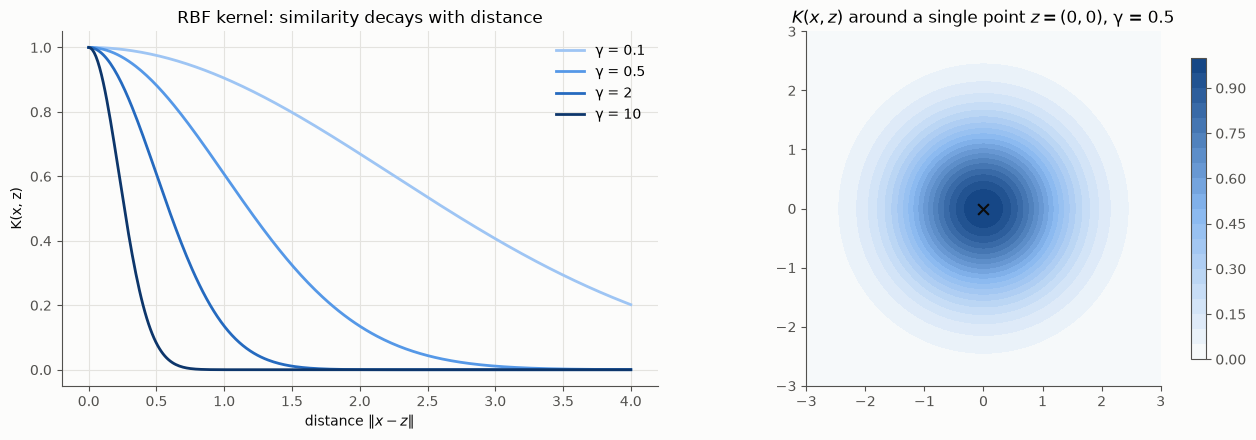

In [9]:
# TODO - OPTIONAL - RAUSNEHMEN?
# Abstaende von 0 bis 4 fuer den Kernel-Plot (300 Punkte)
d = np.linspace(0, 4, 300)
# Mehrere Werte fuer gamma (Kernelbreite) zum Vergleich
gammas = [0.1, 0.5, 2, 10]
# Eine Farbe pro gamma: hell -> dunkel = kleines -> grosses gamma
shades = ["#9ec5f4", "#5598e7", "#256abf", "#0d366b"]   # ein Farbton, hell -> dunkel = kleines -> grosses gamma

# Zwei Plots: Kernelkurven gegen den Abstand (links) und ein 2-D Kernel-Buckel (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
# Links: K = exp(-gamma * d^2) fuer jedes gamma zeichnen; grosses gamma faellt schneller gegen null
for g, c in zip(gammas, shades):
    ax1.plot(d, np.exp(-g * d ** 2), color=c, lw=2, label=f"γ = {g}")
ax1.set_xlabel(r"distance $\|x - z\|$"); ax1.set_ylabel("K(x, z)")
ax1.set_title("RBF kernel: similarity decays with distance")
ax1.legend()

# Kernel-"Buckel" eines einzelnen Punktes in 2-D fuer ein gamma
# Gitter aus 2-D Punkten um den Ursprung
xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
# RBF-Kernelwerte mit gamma = 0.5 zwischen jedem Gitterpunkt und dem Zentrum z = (0, 0)
K = np.exp(-0.5 * (xx ** 2 + yy ** 2))
# Gefuellter Konturplot der Kernelwerte mit eigener Colormap (hell -> dunkelblau)
im = ax2.contourf(xx, yy, K, levels=20, cmap=LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#86b6ef", "#104281"]))
# Das Zentrum z = (0, 0) mit einem Kreuz markieren
ax2.scatter([0], [0], c=BLACK, marker="x", s=60)
ax2.set_title(r"$K(x, z)$ around a single point $z = (0,0)$, γ = 0.5")
ax2.set_aspect("equal"); ax2.grid(False)
# Farbskala der Kernelwerte anzeigen
fig.colorbar(im, ax=ax2, shrink=0.85)
# Abstand anpassen und anzeigen
plt.tight_layout()
plt.show()

## 2.5 Training einer SVM mit RBF-Kernel

train accuracy: 0.981
test  accuracy: 0.978
support vectors: 37 of 210 training points


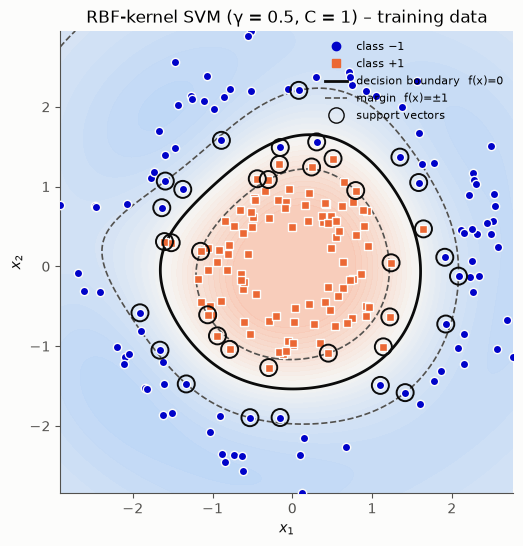

In [10]:
# (1) Train / Testset Generierung
#     stratify: splitte gleichmaessig ueber alle Klassen, nicht nur ueber alle Daten
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(X_nl, y_nl, test_size=0.3, stratify=y_nl, random_state=0)

# (2) RBF-SVM mit gamma = 0.5 (Kernelbreite) und 
#                 C = 1 (Strafparameter fuer Margin-Verletzungen) trainieren
rbf = SVC(kernel="rbf", gamma=0.5, C=1).fit(Xn_tr, yn_tr)

# (3) Debugging
print(f"train accuracy: {rbf.score(Xn_tr, yn_tr):.3f}")
print(f"test  accuracy: {rbf.score(Xn_te, yn_te):.3f}")
print(f"support vectors: {len(rbf.support_)} of {len(yn_tr)} training points")

# (4) Plot
fig, ax = plt.subplots(figsize=(6.5, 6))
plot_svm(ax, rbf, Xn_tr, yn_tr, "RBF-kernel SVM (γ = 0.5, C = 1) – training data")
ax.legend(handles=legend_handles(), loc="upper right", fontsize=8)
ax.set_aspect("equal")
plt.show()

The boundary is now a closed curve around the inner ring. Only the points near the boundary are support vectors.

### Verifying the formula
We can recompute $f(x) = \sum_i \alpha_i y_i K(x_i, x) + b$ by hand from the fitted support vectors, and
visualise how the individual Gaussian bumps add up.

max |manual - sklearn| = 2.220446049250313e-15


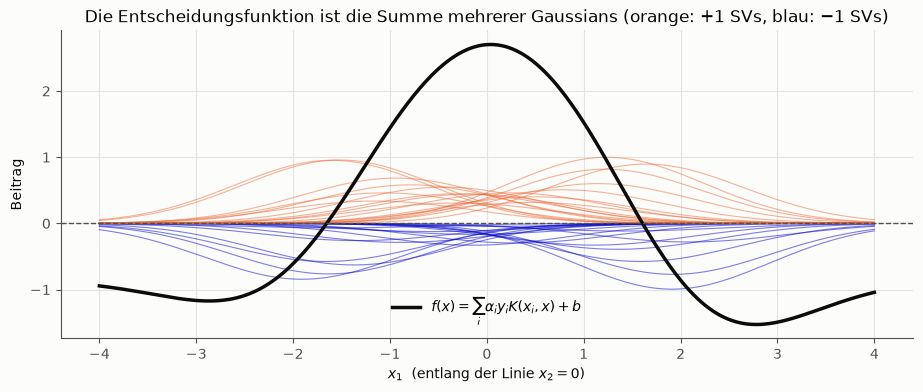

In [11]:
# OPTIONAL - RAUSNEHMEN?
# (1) Funktion: RBF-Kernelmatrix 
# K[i, j] = exp(-gamma * ||A_i - B_j||^2) 
# fuer alle Paare von Zeilen aus A und B
def rbf_kernel(A, B, gamma):
    # Quadrierte euklidische Abstaende ueber ||a||^2 + ||b||^2 - 2 a.b 
    sq = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    # Quadrierte Abstaende in Aehnlichkeiten zwischen 0 und 1 
    return np.exp(-gamma * sq)

# (2) Kernelwerte zwischen jedem Support Vektor und jedem Testpunkt berechnen
#     (Form: n_SV x n_test)
K_te = rbf_kernel(rbf.support_vectors_, Xn_te, gamma=0.5)      # (n_SV, n_test)

# (3) Entscheidungsfunktion: sum_i alpha_i y_i K(x_i, x) + b
f_manual = rbf.dual_coef_[0] @ K_te + rbf.intercept_[0]

# (4) Debugging: Pruefen, rbf_kernel() == decision_function von scikit-learn
print("max |manual - sklearn| =", np.abs(f_manual - rbf.decision_function(Xn_te)).max())

# (5) Plot der Entscheidungsfunktion
# 400 Punkte auf der Linie x2 = 0, x1 von -4 bis 4
line = np.c_[np.linspace(-4, 4, 400), np.zeros(400)]

# (5.1) Beitrag und Graph jedes Support Vektors entlang der Linie
contrib = rbf.dual_coef_[0][:, None] * rbf_kernel(rbf.support_vectors_, line, 0.5)
fig, ax = plt.subplots(figsize=(11, 4))
for c, a in zip(contrib, rbf.dual_coef_[0]):
    ax.plot(line[:, 0], c, color=COLOR_C_2 if a > 0 else COLOR_C_1, lw=0.8, alpha=0.5)

# (5.2) Summe aller SV Beitraege zeichnen
ax.plot(line[:, 0], contrib.sum(0) + rbf.intercept_[0], color=BLACK, lw=2.5, label=r"$f(x) = \sum_i \alpha_i y_i K(x_i, x) + b$")

# (5.3) Nullinie: dort wechselt f(x) das Vorzeichen (die Entscheidungsgrenze)
ax.axhline(0, color=GREY, lw=1, ls="--")
ax.set_xlabel("$x_1$  (entlang der Linie $x_2 = 0$)"); ax.set_ylabel("Beitrag")
ax.set_title("Die Entscheidungsfunktion ist die Summe mehrerer Gaussians (orange: +1 SVs, blau: −1 SVs)")
ax.legend(loc="lower center")
plt.show()

Along the line $x_2 = 0$ the sum $f(x)$ is positive in the middle (inner ring, class $+1$) and negative
further out (outer ring, class $-1$). It crosses $0$ at the decision boundary.

## 2.6 Rolle der Parameter $\gamma$ und $C$

The RBF-SVM has two hyper-parameters:

- $\gamma$ – kernel width (how far each point's influence reaches)
- $C$ – penalty for margin violations (as in the linear case)

Both control the **bias–variance trade-off**:

| | small value | large value |
|---|---|---|
| $\gamma$ | smooth, nearly linear boundary → **underfitting** | wiggly islands around single points → **overfitting** |
| $C$ | wide soft margin, more regularisation | fits the training data tightly |

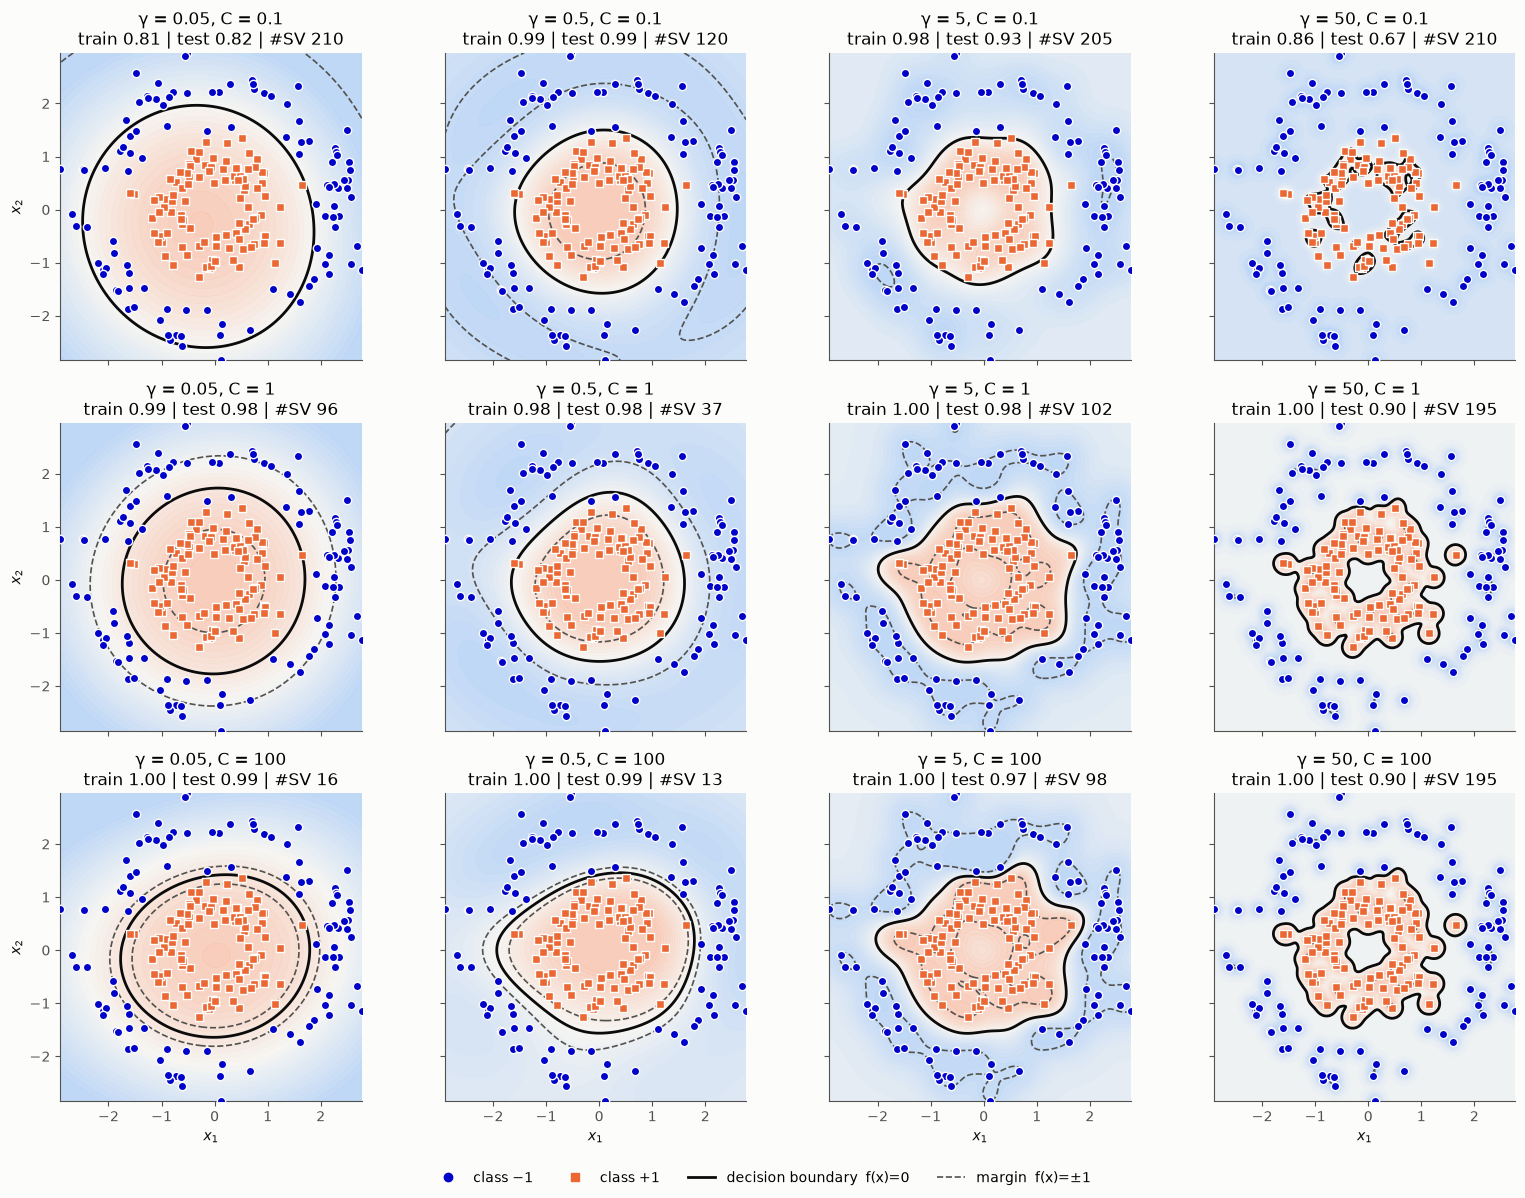

In [12]:
# (1) Parameter fuer 
#     gamma (Spalten des Gitters) und 
#     C     (Zeilen des Gitters) 
#     zum Vergleich
gammas = [0.05, 0.5, 5, 50]
Cs = [0.1, 1, 100]

# (2) Plots fuer C (pro Zeile) und gamma (pro Spalte)
#     Fuer jede Kombination trainieren wir eine SVM!
fig, axes = plt.subplots(len(Cs), len(gammas), figsize=(16, 12), sharex=True, sharey=True)
for i, C in enumerate(Cs):
    for j, gamma in enumerate(gammas):
        # RBF-SVM mit diesem gamma und C auf den Trainingsdaten trainieren
        mdl = SVC(kernel="rbf", gamma=gamma, C=C).fit(Xn_tr, yn_tr)

        plot_svm(axes[i, j], mdl, Xn_tr, yn_tr, show_sv=False, res=200,
                 title=f"γ = {gamma}, C = {C}\ntrain {mdl.score(Xn_tr, yn_tr):.2f} | test {mdl.score(Xn_te, yn_te):.2f} | #SV {len(mdl.support_)}")
        axes[i, j].set_aspect("equal")

        # y-Beschriftung nur in der ersten Spalte und 
        # x-Beschriftung nur in der untersten Zeile behalten
        if j: axes[i, j].set_ylabel("")
        if i < len(Cs) - 1: axes[i, j].set_xlabel("")

# (3) Formatierung
fig.legend(handles=legend_handles(False), loc="lower center", ncol=4)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

- **Left column (γ = 0.05):** the bumps are very wide, so the boundary is a smooth ellipse. Combined with a small
  $C$ (top-left) the model is too stiff and **underfits**: it misplaces the boundary and every point becomes a support vector.
- **Middle columns:** a smooth closed curve that follows the gap between the rings – good train *and* test accuracy.
- **Right column (γ = 50):** each point only influences its immediate neighbourhood; the boundary breaks into
  ragged islands (note the hole in the middle and the small isolated blobs). Training accuracy is perfect but test
  accuracy drops – classic **overfitting**. Almost all points become support vectors.
- Larger $C$ makes the model fit the training data more tightly, which pushes in the same direction.

## 2.7 Cross-Validierung, um $\gamma$ und $C$ zu bestimmen

The standard way to select hyper-parameters is a **grid search with k-fold cross-validation** on the training
set only; the test set is used once at the end. (Tip: on real data, standardise the features first – e.g. with a
`StandardScaler` in a `Pipeline` – because the RBF kernel depends on Euclidean distances. Our two features are
already on the same scale.)

best parameters: {'C': 100.0, 'gamma': 0.316}
best CV accuracy: 1.000
test accuracy   : 0.978


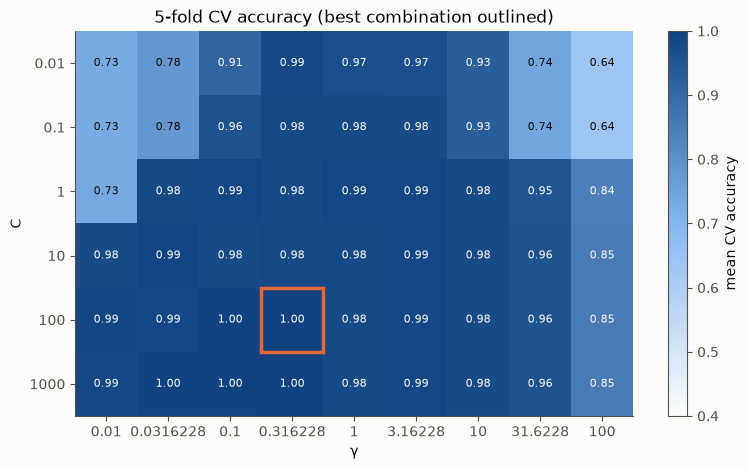

In [13]:
# TODO OPTIONAL WUERDE ICH RAUSNEHMEN AB HIER
# Hyperparameter-Raster: 6 Werte fuer C und 9 Werte fuer gamma, beide logarithmisch verteilt (10^-2 ... 10^3 bzw. 10^-2 ... 10^2)
param_grid = {"C": np.logspace(-2, 3, 6), "gamma": np.logspace(-2, 2, 9)}
# Grid Search: probiert jedes (C, gamma) Paar mit 5-facher stratifizierter Kreuzvalidierung, nur auf den Trainingsdaten
search = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=0))
# Suche ausfuehren (trainiert 6 x 9 x 5 Modelle)
search.fit(Xn_tr, yn_tr)
# Beste Hyperparameter-Kombination aus der Kreuzvalidierung
print("best parameters:", {k: round(float(v), 3) for k, v in search.best_params_.items()})
# Mittlere Kreuzvalidierungs-Genauigkeit der besten Kombination
print(f"best CV accuracy: {search.best_score_:.3f}")
# Genauigkeit des besten Modells auf dem unberuehrten Testset (nur einmal, am Ende, verwendet)
print(f"test accuracy   : {search.score(Xn_te, yn_te):.3f}")

# Die flache Liste der mittleren CV-Werte in eine (C x gamma) Tabelle fuer die Heatmap umformen
scores = search.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
# Heatmap-Abbildung
fig, ax = plt.subplots(figsize=(9, 5))
# Die Werte als Farben zeichnen; die festen vmin/vmax halten die Farbskala vergleichbar
im = ax.imshow(scores, cmap=LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#86b6ef", "#104281"]),
               vmin=0.4, vmax=1, aspect="auto")
# Spalten mit gamma-Werten und Zeilen mit C-Werten beschriften
ax.set_xticks(range(len(param_grid["gamma"])), [f"{g:g}" for g in param_grid["gamma"]])
ax.set_yticks(range(len(param_grid["C"])), [f"{c:g}" for c in param_grid["C"]])
ax.set_xlabel("γ"); ax.set_ylabel("C"); ax.grid(False)
# Den Wert in jede Zelle schreiben; bei dunklen Zellen weisser Text fuer bessere Lesbarkeit
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="#fcfcfb" if scores[i, j] > 0.8 else BLACK)
# Zeilen- und Spaltenindex der besten (C, gamma) Kombination bestimmen
bi = list(param_grid["C"]).index(search.best_params_["C"])
bj = list(param_grid["gamma"]).index(search.best_params_["gamma"])
# Beste Zelle mit einem orangen Rechteck umranden
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec=COLOR_C_2, lw=2.5))
ax.set_title("5-fold CV accuracy (best combination outlined)")
# Farbskala mit den Scores anzeigen
fig.colorbar(im, ax=ax, label="mean CV accuracy")
plt.show()

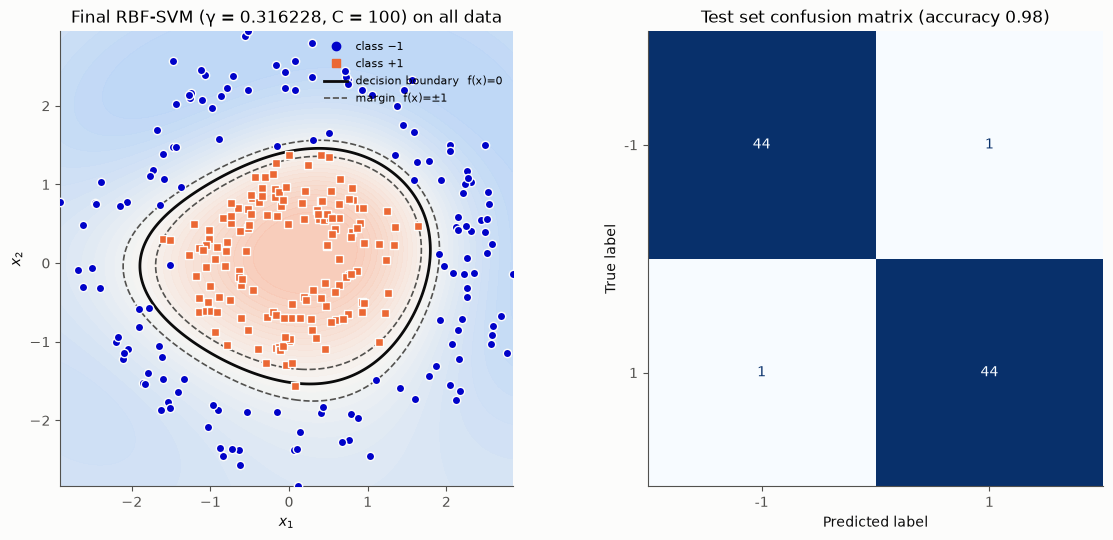

In [14]:
# Das Modell mit den besten Hyperparametern, von GridSearchCV auf dem gesamten Trainingsset neu trainiert
best = search.best_estimator_
# Zwei Plots: Entscheidungsbereiche (links) und Confusion Matrix auf dem Testset (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))
# Links: Entscheidungsbereiche des finalen Modells auf den Ringdaten; gamma und C stehen im Titel
plot_svm(ax1, best, X_nl, y_nl, f"Final RBF-SVM (γ = {best.gamma:g}, C = {best.C:g}) on all data", show_sv=False)
ax1.legend(handles=legend_handles(False), loc="upper right", fontsize=8)
ax1.set_aspect("equal")
# Rechts: Confusion Matrix auf dem Testset (Zeilen = wahre Klasse, Spalten = vorhergesagte Klasse)
ConfusionMatrixDisplay.from_estimator(best, Xn_te, yn_te, ax=ax2, cmap="Blues", colorbar=False)
ax2.set_title(f"Test set confusion matrix (accuracy {best.score(Xn_te, yn_te):.2f})"); ax2.grid(False)
# Abstand anpassen und anzeigen
plt.tight_layout()
plt.show()

---
# Zusammenfassung

| | Linear SVM | RBF-kernel SVM |
|---|---|---|
| Decision function | $f(x) = w^\top x + b$ | $f(x) = \sum_i \alpha_i y_i \exp(-\gamma\lVert x_i - x\rVert^2) + b$ |
| Boundary in input space | hyperplane | arbitrary smooth curve / surface |
| Hyper-parameters | $C$ | $C$, $\gamma$ |
| Feature space | input space | infinite-dimensional (implicit) |

**Key take-aways**

1. An SVM chooses the separating hyperplane with the **maximum margin** $2/\lVert w\rVert$, found by minimising
   $\tfrac12\lVert w\rVert^2$ subject to $y_i(w^\top x_i+b)\ge 1$.
2. The **soft margin** (slack variables / hinge loss) handles noise and overlap; $C$ trades margin width
   against violations.
3. The **dual** shows that the solution $w = \sum_i\alpha_i y_i x_i$ depends only on the **support vectors**,
   and only through **inner products**.
4. The **kernel trick** replaces inner products with a kernel $K(x,z)=\phi(x)^\top\phi(z)$, giving a linear
   classifier in a (possibly infinite-dimensional) feature space without ever computing $\phi$.
5. The **RBF kernel** measures similarity by distance; $\gamma$ and $C$ control under- vs. over-fitting and are
   chosen by **cross-validation**.